# Q-learner experiments

All reusable code now lives in `code_exploration/` modules:
`overcooked_utils.py` (env, predicates, motion goals, feasible subtasks), `argumentation.py`, `qlearner.py` (abstract state, Learner, SubtaskTracker, QAgent), `experiment.py` (run_episode, evaluate, train, baselines).
Tests: `cd code_exploration && python -m pytest tests`.

In [ ]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "..")          # modules live in code_exploration/

import json
import numpy as np
from overcooked_ai_py.agents.agent import GreedyHumanModel

from overcooked_utils import ACTIONS, make_env, predicates, feasible_actions, motion_goals
from qlearner import Learner, SubtaskTracker, QAgent, abstract_state
from experiment import StayAgent, run_episode, evaluate, eps_at, train, save_result, RESULTS_DIR

In [ ]:
env = make_env("asymmetric_advantages")
env.reset()
print(env.mdp.state_string(env.state))

In [ ]:
# quick check: short run, and evaluation must not change the Q-table
res, trained = train("cramped_room", seed=0, n_episodes=50, eval_every=25)
before = dict(trained.learner.q_table)
trained.eps = 0.0
env_check = make_env("cramped_room")
print(run_episode(trained, GreedyHumanModel(env_check.mlam), env_check, learn=False))
assert dict(trained.learner.q_table) == before, "evaluation changed the Q-table"
print("eval leaves Q-table unchanged ✓")

In [ ]:
# Full run: learner over seeds + baselines, per layout. Saves JSON via save_result -> code_exploration/results/q_learner/
LAYOUTS = ["cramped_room", "asymmetric_advantages"]
SEEDS = [0, 1, 2]

results = {}
for layout in LAYOUTS:
    runs = []
    for seed in SEEDS:
        res, _ = train(layout, seed, verbose=False)
        runs.append(res)
        save_result(res, f"{layout}_seed{seed}")
        print(f"{layout} seed {seed}: final eval soups {res['curve']['mean'][-1]:.2f}, Q entries {res['q_size']}")

    env_b = make_env(layout)
    np.random.seed(0)
    baselines = {
        "greedy + greedy": evaluate(GreedyHumanModel(env_b.mlam), GreedyHumanModel(env_b.mlam), env_b),
        "random + greedy": evaluate(QAgent(env_b.mlam, Learner(0, 0.1, 0.99), eps=1.0), GreedyHumanModel(env_b.mlam), env_b),
        "stay + greedy":   evaluate(StayAgent(), GreedyHumanModel(env_b.mlam), env_b),
    }
    save_result(baselines, f"{layout}_baselines")
    print(layout, {k: f"{m:.2f} ± {s:.2f}" for k, (m, s) in baselines.items()})
    results[layout] = {"runs": runs, "baselines": baselines}

Computing MediumLevelActionManager
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Computing MotionPlanner
Compu

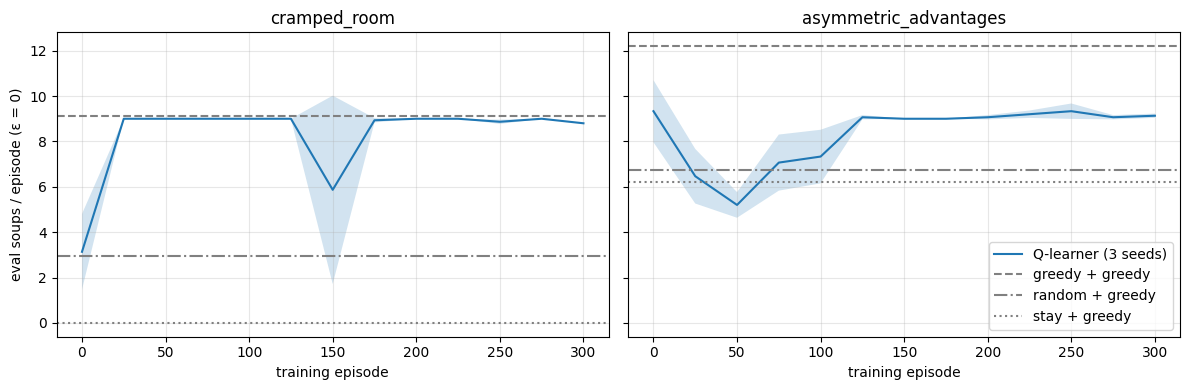

In [ ]:
# Learning curves: mean over seeds (± std across seeds), baselines as dashed lines
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, (layout, r) in zip(axes, results.items()):
    eps_axis = r["runs"][0]["curve"]["episode"]
    means = np.array([run["curve"]["mean"] for run in r["runs"]])
    mu, sd = means.mean(axis=0), means.std(axis=0)
    ax.plot(eps_axis, mu, label=f"Q-learner ({len(r['runs'])} seeds)")
    ax.fill_between(eps_axis, mu - sd, mu + sd, alpha=0.2)
    for (name, (m, _)), ls in zip(r["baselines"].items(), ["--", "-.", ":"]):
        ax.axhline(m, linestyle=ls, color="gray", label=name)
    ax.set_title(layout)
    ax.set_xlabel("training episode")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("eval soups / episode (ε = 0)")
axes[-1].legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "q_learner" / "learning_curves.png", dpi=150)
plt.show()